# 와인 품종 분류 실습 (딥러닝 + 원핫인코딩)

ex_0914 와인 실습을 Keras 신경망으로 다시 해 보는 노트북입니다. 1~5단계 구성은 그대로 두고, 딥러닝에 필요한 단계를 추가했습니다.

## 이 문제는 어떤 유형인가

**다중 분류(multi-class classification)** 입니다. 화학 성분 13개로 와인 품종 3개(1, 2, 3) 중 하나를 맞힙니다. 품종 번호는 숫자로 적혀 있지만 크기에 의미가 없는 이름표라서 회귀가 아니라 분류입니다.

| 구분 | 이진 분류 (당뇨) | 다중 분류 (와인) |
| --- | --- | --- |
| 정답 형태 | 0 / 1 그대로 | 원핫: [1,0,0], [0,1,0], [0,0,1] |
| 출력층 | `Dense(1, activation='sigmoid')` | `Dense(3, activation='softmax')` |
| 손실함수 | `binary_crossentropy` | `categorical_crossentropy` |
| 예측 읽는 법 | 확률 0.5 이상이면 1 | 확률이 가장 큰 칸 (argmax) |

## ex_0914에서 달라진 점

1. **정답(y)을 원핫인코딩합니다.** 입력 13개는 연속된 숫자라서 원핫 대상이 아닙니다.
2. **입력을 표준화(StandardScaler)합니다.** 신경망은 값의 범위 차이에 민감합니다.
3. **모델이 Keras 신경망입니다.** 마지막에 기존 랜덤포레스트, 로지스틱 회귀, KNN과 비교합니다.

위에서부터 차례로 실행하세요. 코랩의 딥러닝은 실행할 때마다 결과가 조금 달라질 수 있습니다.

In [1]:
# [0단계] 코랩 준비: 구글 드라이브 연결과 라이브러리 불러오기
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"     # 텐서플로의 안내 메시지를 줄입니다

DRIVE_PATH = "/content/drive/MyDrive/Colab Notebooks/wine.csv"   # 원래 실습에서 쓰던 경로

try:
    from google.colab import drive
    drive.mount('/content/drive')    # 처음 실행하면 구글 계정 연결 창이 뜹니다
except ImportError:
    pass                             # 코랩이 아니면 건너뜁니다

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

tf.get_logger().setLevel("ERROR")            # 학습과 무관한 경고 문구를 숨깁니다
print("TensorFlow 버전:", tf.__version__)

TensorFlow 버전: 2.21.0


## [1단계] 데이터 불러오기
드라이브 경로에 `wine.csv`가 없으면 현재 폴더에서 찾고, 그래도 없으면 scikit-learn에 들어 있는 같은 와인 데이터(178개, 품종 3개)를 같은 column 이름으로 불러옵니다.

In [2]:
# [1단계] 데이터 불러오기
candidates = [DRIVE_PATH, "wine.csv"]
CSV_PATH = next((p for p in candidates if os.path.exists(p)), None)

if CSV_PATH:
    df = pd.read_csv(CSV_PATH)
    print("읽은 파일:", CSV_PATH)
else:
    from sklearn.datasets import load_wine
    wine = load_wine(as_frame=True)
    cols = ["Alcohol", "Malic.acid", "Ash", "Acl", "Mg", "Phenols", "Flavanoids",
            "Nonflavanoid.phenols", "Proanth", "Color.int", "Hue", "OD", "Proline"]
    df = wine.data.set_axis(cols, axis=1)
    df.insert(0, "Wine", wine.target + 1)            # 품종 번호를 1, 2, 3으로 맞춥니다
    df[["Mg", "Proline"]] = df[["Mg", "Proline"]].astype(int)
    print("wine.csv가 없어 scikit-learn의 와인 데이터를 불러왔습니다.")

# 독립 변수(X)와 타겟 변수(y) 분리
X = df.drop("Wine", axis=1)
y = df["Wine"]

print("데이터 형태 (행, 열):", df.shape)
print("품종별 개수:", y.value_counts().sort_index().to_dict())
print("상위 5개 데이터 미리보기:")
display(df.head())

읽은 파일: wine.csv
데이터 형태 (행, 열): (178, 14)
품종별 개수: {1: 59, 2: 71, 3: 48}
상위 5개 데이터 미리보기:


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


## [1-1단계] 정답 원핫인코딩
신경망의 출력층은 품종마다 칸이 하나씩, 모두 3칸입니다. 정답도 같은 모양이어야 하므로 품종 번호를 원핫으로 바꿉니다.

**주의:** `to_categorical`은 0부터 센다고 가정합니다. 품종이 1, 2, 3인 상태로 넣으면 쓰지 않는 0번 칸이 생겨 4칸이 됩니다. 그래서 1을 빼서 0, 1, 2로 만든 뒤 원핫합니다.

In [3]:
# [1-1단계] 정답 원핫인코딩

# 잘못된 예: 1, 2, 3을 그대로 넣으면 4칸이 됩니다
wrong = to_categorical(y)
print("1, 2, 3을 그대로 넣었을 때 모양:", wrong.shape, "  첫 행:", wrong[0])

# 올바른 예: 0, 1, 2로 바꾼 뒤 3칸으로 원핫
y_index = y - 1                                  # 품종 1, 2, 3 -> 0, 1, 2
Y = to_categorical(y_index, num_classes=3)
print("0, 1, 2로 바꾼 뒤 모양:", Y.shape)

# 품종마다 한 명씩 확인합니다
sample = [0, 59, 130]                            # 품종 1, 2, 3의 첫 번째 데이터
display(pd.DataFrame(Y[sample].astype(int),
                     index=[f"{i}번 행 (품종 {y[i]})" for i in sample],
                     columns=["품종1 칸", "품종2 칸", "품종3 칸"]))

1, 2, 3을 그대로 넣었을 때 모양: (178, 4)   첫 행: [0. 1. 0. 0.]
0, 1, 2로 바꾼 뒤 모양: (178, 3)


,품종1 칸,품종2 칸,품종3 칸
0번 행 (품종 1),1,0,0
59번 행 (품종 2),0,1,0
130번 행 (품종 3),0,0,1


## [2단계] 데이터셋 분할 (학습용 / 테스트용)
기존 실습과 비교할 수 있도록 `test_size=0.2`, `random_state=42`를 그대로 씁니다. 입력(X), 원핫 정답(Y), 원래 품종 번호(y)를 한 번에 나누면 세 가지가 같은 행으로 나뉩니다.

In [4]:
# [2단계] 데이터셋 분할 (학습용 / 테스트용)
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y, test_size=0.2, random_state=42)

print(f"학습용 데이터 크기: X_train {X_train.shape}, Y_train {Y_train.shape}")
print(f"테스트용 데이터 크기: X_test {X_test.shape}, Y_test {Y_test.shape}")
print("테스트용 품종별 개수:", y_test.value_counts().sort_index().to_dict())

학습용 데이터 크기: X_train (142, 13), Y_train (142, 3)
테스트용 데이터 크기: X_test (36, 13), Y_test (36, 3)
테스트용 품종별 개수: {1: 14, 2: 14, 3: 8}


## [2-1단계] 입력 표준화 (StandardScaler)
Proline은 수백에서 1,680까지인데 Hue는 0.5에서 1.7 사이입니다. 이대로 넣으면 큰 값을 가진 column이 학습을 좌우합니다. 표준화하면 모든 column이 평균 0, 표준편차 1 근처로 맞춰집니다.

표준화 기준(평균, 표준편차)은 **학습용 데이터로만** 정합니다. 테스트 데이터는 그 기준으로 변환만 합니다.

In [5]:
# [2-1단계] 입력 표준화
from sklearn.preprocessing import StandardScaler

print("표준화 전 범위 (일부 column):")
display(X_train[["Proline", "Mg", "Hue", "Nonflavanoid.phenols"]].agg(["min", "max"]).round(2))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # 학습용: 기준을 정하고 변환
X_test_s = scaler.transform(X_test)           # 테스트용: 같은 기준으로 변환만

print("표준화 후 학습용 데이터의 평균과 표준편차 (일부 column):")
display(pd.DataFrame(X_train_s, columns=X.columns)[["Proline", "Mg", "Hue", "Nonflavanoid.phenols"]]
        .agg(["mean", "std"]).round(2))

표준화 전 범위 (일부 column):


,Proline,Mg,Hue,Nonflavanoid.phenols
min,278,70,0.48,0.13
max,1547,162,1.71,0.66


표준화 후 학습용 데이터의 평균과 표준편차 (일부 column):


,Proline,Mg,Hue,Nonflavanoid.phenols
mean,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


## [3단계] 모델 객체 생성
입력 13개 → 은닉층 16개 → 은닉층 8개 → 출력 3개인 신경망입니다. 출력층의 softmax는 3칸의 값을 더해서 1이 되는 확률로 바꿉니다.

In [6]:
# [3단계] 모델 객체 생성
keras.utils.set_random_seed(42)       # 결과 재현을 위해 시작값을 고정합니다

model = keras.Sequential([
    keras.Input(shape=(13,)),                  # 입력: 화학 성분 13개
    layers.Dense(16, activation="relu"),       # 은닉층 1
    layers.Dense(8, activation="relu"),        # 은닉층 2
    layers.Dense(3, activation="softmax"),     # 출력층: 품종 3개의 확률
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 387 (1.51 KB)

 Trainable params: 387 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

파라미터 수는 (입력 수 × 노드 수 + 노드 수)입니다. 13×16+16 = 224, 16×8+8 = 136, 8×3+3 = 27이라 모두 387개입니다.

## [3-1단계] 모델 컴파일
원핫 정답과 softmax 출력을 비교하는 손실함수는 `categorical_crossentropy`입니다.

In [7]:
# [3-1단계] 모델 컴파일
model.compile(optimizer="adam",
              loss="categorical_crossentropy",   # 원핫 정답 + softmax 출력에 쓰는 손실함수
              metrics=["accuracy"])

## [4단계] 모델 학습
학습용 데이터 142개 중 20%(28개)는 `validation_split`으로 떼어 두고, 학습 중간에 처음 보는 데이터에서도 잘 맞히는지 확인합니다.

In [8]:
# [4단계] 모델 학습
history = model.fit(X_train_s, Y_train,
                    epochs=100,              # 학습 데이터 전체를 100번 반복
                    batch_size=16,           # 16개씩 묶어서 가중치를 갱신
                    validation_split=0.2,    # 학습용의 20%는 검증용으로 사용
                    verbose=0)               # 진행 표시를 끕니다. 1로 바꾸면 매 반복이 보입니다

last = {k: round(v[-1], 3) for k, v in history.history.items()}
print("딥러닝 모델 학습이 완료되었습니다.")
print("마지막 반복의 결과:", last)

딥러닝 모델 학습이 완료되었습니다.
마지막 반복의 결과: {'accuracy': 1.0, 'loss': 0.011, 'val_accuracy': 0.931, 'val_loss': 0.126}


## [4-1단계] 학습 곡선 보기
학습(train)과 검증(validation)의 손실이 함께 내려가면 잘 학습된 것입니다. 학습 손실은 계속 내려가는데 검증 손실만 다시 올라가면 학습 데이터에 지나치게 맞춘 과대적합입니다.

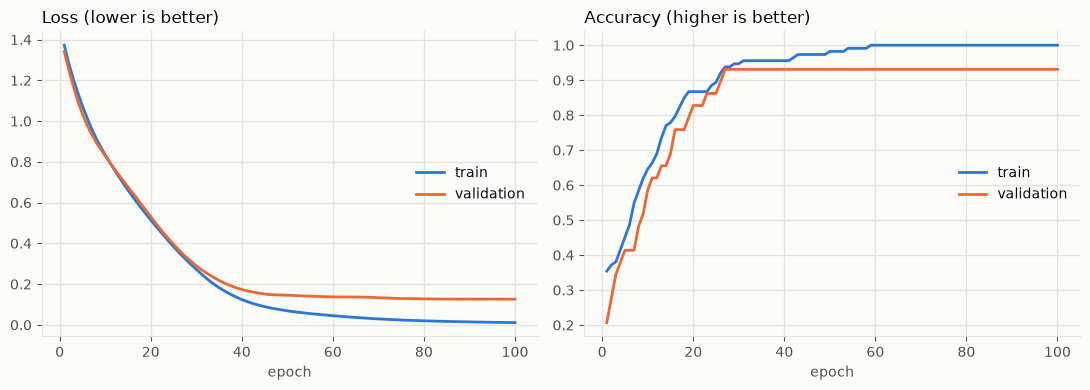

In [9]:
# [4-1단계] 학습 곡선 보기
import matplotlib.pyplot as plt

TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"         # 학습 = 파랑, 검증 = 주황
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

epochs = np.arange(1, len(history.history["loss"]) + 1)
panels = [("loss", "Loss (lower is better)"), ("accuracy", "Accuracy (higher is better)")]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), facecolor=SURFACE)
for ax, (key, title) in zip(axes, panels):
    train, val = history.history[key], history.history["val_" + key]
    ax.set_facecolor(SURFACE)
    ax.plot(epochs, train, color=TRAIN_COLOR, linewidth=2, label="train")
    ax.plot(epochs, val, color=VAL_COLOR, linewidth=2, label="validation")
    ax.set_title(title, loc="left", color=INK, fontsize=12)
    ax.set_xlabel("epoch", color=MUTED)
    ax.grid(True, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)
    ax.legend(frameon=False, labelcolor=INK, loc="center right")

plt.tight_layout()
plt.show()

## [5단계] 예측 및 성능 평가
`predict`는 품종 3개의 확률을 돌려줍니다. 가장 큰 확률의 칸 번호(argmax)에 1을 더하면 품종 번호가 됩니다.

In [10]:
# [5단계] 예측 및 성능 평가
from sklearn.metrics import classification_report, confusion_matrix

probs = model.predict(X_test_s, verbose=0)        # 테스트 데이터마다 품종 3개의 확률
pred_dl = probs.argmax(axis=1) + 1                # 가장 큰 칸 번호(0, 1, 2) -> 품종 번호(1, 2, 3)

print("예측 확률 미리보기 (상위 5개):")
preview = pd.DataFrame(probs[:5].round(3), columns=["품종1 확률", "품종2 확률", "품종3 확률"])
preview["예측 품종"] = pred_dl[:5]
preview["실제 품종"] = y_test.values[:5]
display(preview)

# 실제 정답(y_test)과 예측 결과(pred_dl)를 비교하여 성능 리포트 출력
print("\n[딥러닝 분류 성능 평가 리포트]")
print(classification_report(y_test, pred_dl))

print("혼동행렬 (행: 실제 품종, 열: 예측 품종)")
display(pd.DataFrame(confusion_matrix(y_test, pred_dl),
                     index=["실제 1", "실제 2", "실제 3"], columns=["예측 1", "예측 2", "예측 3"]))

예측 확률 미리보기 (상위 5개):


,품종1 확률,품종2 확률,품종3 확률,예측 품종,실제 품종
0,0.996,0.003,0.001,1,1
1,0.823,0.080,0.098,1,1
2,0.000,0.005,0.994,3,3
3,0.998,0.002,0.000,1,1
4,0.000,1.000,0.000,2,2



[딥러닝 분류 성능 평가 리포트]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00        14
           3       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

혼동행렬 (행: 실제 품종, 열: 예측 품종)


,예측 1,예측 2,예측 3
실제 1,14,0,0
실제 2,0,14,0
실제 3,0,0,8


## [6단계] 기존 실습 모델과 비교
같은 분할로 ex_0914의 모델과 비교합니다. 표준화가 얼마나 중요한지 보려고, 같은 신경망을 표준화 없이 학습한 결과와 표준화한 KNN도 함께 넣었습니다.

In [11]:
# [6단계] 기존 실습 모델과 비교
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # 기존 로지스틱 회귀의 수렴 경고를 숨깁니다

def build_model():
    m = keras.Sequential([keras.Input(shape=(13,)),
                          layers.Dense(16, activation="relu"),
                          layers.Dense(8, activation="relu"),
                          layers.Dense(3, activation="softmax")])
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

# 같은 신경망을 표준화 없이 학습
keras.utils.set_random_seed(42)
raw_model = build_model()
raw_model.fit(X_train.values, Y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=0)
pred_raw_dl = raw_model.predict(X_test.values, verbose=0).argmax(axis=1) + 1

results = [
    ("랜덤포레스트 (ex_0914)", "원본",
     RandomForestClassifier(random_state=42).fit(X_train, y_train).predict(X_test)),
    ("로지스틱 회귀 (ex_0914)", "원본",
     LogisticRegression(max_iter=200, random_state=42).fit(X_train, y_train).predict(X_test)),
    ("KNN (ex_0914)", "원본",
     KNeighborsClassifier().fit(X_train, y_train).predict(X_test)),
    ("KNN", "표준화",
     KNeighborsClassifier().fit(X_train_s, y_train).predict(X_test_s)),
    ("딥러닝", "원본 (표준화 없음)", pred_raw_dl),
    ("딥러닝 (이 노트북)", "표준화", pred_dl),
]
table = pd.DataFrame([(name, data, accuracy_score(y_test, pred)) for name, data, pred in results],
                     columns=["모델", "입력", "테스트 정확도"])
display(table.round(3))

,모델,입력,테스트 정확도
0,랜덤포레스트 (ex_0914),원본,1.000
1,로지스틱 회귀 (ex_0914),원본,0.972
2,KNN (ex_0914),원본,0.722
3,KNN,표준화,0.944
4,딥러닝,원본 (표준화 없음),0.889
5,딥러닝 (이 노트북),표준화,1.000


## [7단계] 원핫 없이 하는 방법도 알아 두기
Keras에는 정답을 원핫으로 바꾸지 않고 0, 1, 2 번호 그대로 쓰는 손실함수 `sparse_categorical_crossentropy`도 있습니다. 내부 계산은 같고 정답의 모양만 다릅니다.

| 정답 형태 | 손실함수 |
| --- | --- |
| 원핫 [0, 1, 0] | `categorical_crossentropy` |
| 번호 1 (0부터 시작) | `sparse_categorical_crossentropy` |

In [12]:
# [7단계] 원핫 없이 번호 그대로 학습하기
keras.utils.set_random_seed(42)
sparse_model = keras.Sequential([keras.Input(shape=(13,)),
                                 layers.Dense(16, activation="relu"),
                                 layers.Dense(8, activation="relu"),
                                 layers.Dense(3, activation="softmax")])
sparse_model.compile(optimizer="adam",
                     loss="sparse_categorical_crossentropy",   # 정답이 번호(0, 1, 2)일 때
                     metrics=["accuracy"])
sparse_model.fit(X_train_s, (y_train - 1).values, epochs=100, batch_size=16,
                 validation_split=0.2, verbose=0)

pred_sparse = sparse_model.predict(X_test_s, verbose=0).argmax(axis=1) + 1
print("정답 모양:", (y_train - 1).values[:5], " (원핫이 아니라 번호)")
print("테스트 정확도:", round(accuracy_score(y_test, pred_sparse), 3))

정답 모양: [2 2 1 2 0]  (원핫이 아니라 번호)
테스트 정확도: 1.0


## 참고: ex_0914의 의사결정나무 회귀에 대해
ex_0914의 마지막 두 셀은 `DecisionTreeRegressor`로 품종 번호를 예측하고 RMSE를 구했습니다. 회귀는 숫자의 크기를 예측하므로 품종 3이 품종 1보다 품종 2와 "가깝다"고 가정합니다. 품종 번호에는 그런 순서가 없어서 이 문제에는 분류 모델이 맞습니다. 그래서 이 노트북에서는 회귀 모델을 다루지 않았습니다.

## 정리

- 와인 데이터는 품종 3개 중 하나를 맞히는 **다중 분류**입니다.
- 딥러닝 다중 분류의 기본 구성은 **정답 원핫인코딩 + `Dense(3, softmax)` + `categorical_crossentropy`** 입니다.
- 원핫 전에 품종 번호를 **0부터 시작**하도록 바꿔야 합니다. 1, 2, 3 그대로 넣으면 4칸이 되어 출력층과 모양이 맞지 않습니다.
- 신경망과 KNN처럼 값의 범위에 민감한 모델은 **표준화**가 결과를 크게 바꿉니다. 6단계 표에서 확인할 수 있습니다.
- 예측 결과는 확률이므로 **argmax로 가장 큰 칸**을 골라 품종 번호로 되돌립니다.

## 더 해볼 것

1. 은닉층 노드 수(16, 8)나 층 수를 바꿔 보고 학습 곡선이 어떻게 달라지는지 보기
2. `epochs`를 300으로 늘려 검증 손실이 다시 올라가는 과대적합이 생기는지 확인하기
3. `train_test_split`에 `stratify=y`를 넣어 품종 비율을 맞춘 분할로 다시 해 보기
4. 출력층의 softmax를 sigmoid로 바꾸면 확률의 합이 어떻게 달라지는지 확인하기